# Assignment 1 — EDA starter
Run `src/get_data.py`, `src/clean.py`, `src/build_features.py` first. One example chart is done; the rest are yours.

In [1]:
import pandas as pd, matplotlib.pyplot as plt
players = pd.read_csv('../data/processed/player_game_logs.csv', parse_dates=['game_date'])
teams = pd.read_csv('../data/processed/team_game_logs.csv', parse_dates=['game_date'])
model = pd.read_csv('../data/processed/model_table.csv', parse_dates=['game_date'])
played = players[players.played == 1]
played.shape, teams.shape, model.shape

((351409, 28), (33316, 24), (343168, 32))

## Example: how spread out are single-game points?

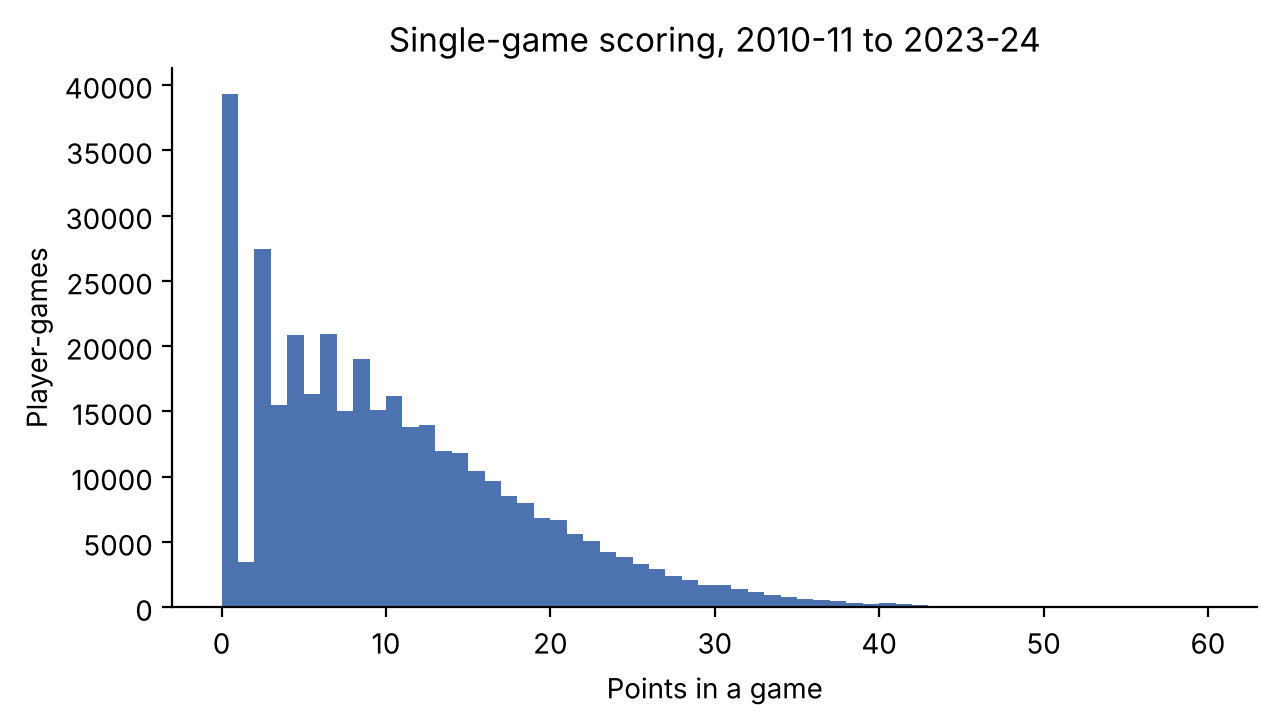

In [2]:
fig, ax = plt.subplots(figsize=(7, 3.5))
played.pts.plot.hist(bins=range(0, 61), ax=ax, color='#4C72B0')
ax.set(xlabel='Points in a game', ylabel='Player-games', title='Single-game scoring, 2010-11 to 2023-24')
ax.spines[['top','right']].set_visible(False)

## Setup for the TODOs
Shared chart style, plus a training-seasons-only table for the analysis cells.

In [3]:
# Shared setup for the TODOs below
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

BLUE, RED, INK, MUTED = '#2a78d6', '#e34948', '#0b0b0b', '#898781'
BLUES = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#6da7ec', '#2a78d6', '#184f95', '#0d366b'])
plt.rcParams.update({
    'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
})

# TODOs 2-4 look at what drives scoring, so they only use the TRAINING seasons.
# Looking at 2023-24 (the test season) while picking features would make our test score look better than it is.
TRAIN = ['2015-16', '2016-17', '2017-18', '2018-19', '2019-20', '2020-21', '2021-22']
train = model[model.season.isin(TRAIN)].copy()
train['diff'] = train.pts - train.pts_l10                 # + means he beat his last-10 average
train['beat'] = (train.pts > train.pts_l10).astype(int)


def diff_bars(ax, g, labels):
    """Average (pts - pts_l10) per bin: blue = above his recent average, red = below. Whiskers = 95% CI."""
    x = np.arange(len(g))
    ci = 1.96 * g['std'] / np.sqrt(g['size'])
    ax.bar(x, g['mean'], width=0.6, color=[BLUE if v >= 0 else RED for v in g['mean']],
           yerr=ci, ecolor=MUTED, capsize=3)
    ax.axhline(0, color='#c3c2b7', lw=1)
    for xi, v, c in zip(x, g['mean'], ci):   # value label just past the end of the whisker
        ax.annotate(f'{v:+.2f}', (xi, v + c if v >= 0 else v - c), xytext=(0, 4 if v >= 0 else -4),
                    textcoords='offset points', ha='center', va='bottom' if v >= 0 else 'top',
                    fontsize=9, color=INK)
    ax.set_xticks(x, labels)
    ax.grid(axis='x', visible=False)


print(f'{len(train):,} training player-games ({TRAIN[0]} to {TRAIN[-1]})')


172,427 training player-games (2015-16 to 2021-22)


## TODO 1 — Minutes vs points
Scatter or hexbin. How much of scoring is just playing time?

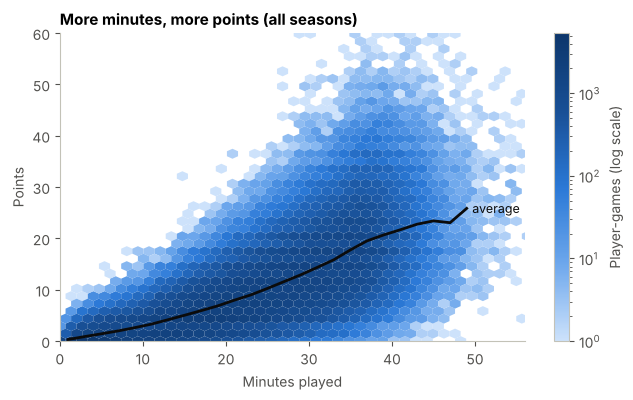

correlation r = 0.73 -> minutes alone explain 53% of the variation in points
league-wide scoring rate: 15.8 points per 36 minutes


In [4]:
fig, ax = plt.subplots(figsize=(7.5, 4))
hb = ax.hexbin(played['min'], played.pts, gridsize=45, bins='log', cmap=BLUES, mincnt=1, linewidths=0)
fig.colorbar(hb, ax=ax, label='Player-games (log scale)')

# average points in each 2-minute bucket (skip thin buckets from deep overtime)
bucket = (played['min'] // 2) * 2 + 1
by_bucket = played.groupby(bucket).pts.agg(['mean', 'size'])
by_bucket = by_bucket[by_bucket['size'] >= 200]
ax.plot(by_bucket.index, by_bucket['mean'], color=INK, lw=2)
ax.annotate('average', (by_bucket.index[-1], by_bucket['mean'].iloc[-1]), xytext=(4, 0),
            textcoords='offset points', va='center', fontsize=9, color=INK)
ax.set(xlabel='Minutes played', ylabel='Points', xlim=(0, 56), ylim=(0, 60),
       title='More minutes, more points (all seasons)')
ax.grid(False)
plt.show()

r = played['min'].corr(played.pts)
print(f'correlation r = {r:.2f} -> minutes alone explain {r**2:.0%} of the variation in points')
print(f'league-wide scoring rate: {36 * played.pts.sum() / played["min"].sum():.1f} points per 36 minutes')


**Takeaway:** Playing time is about half the story: minutes alone explain ~53% of the variation in points (r = 0.73), so anything that hints at a player's minutes before tipoff is worth a feature.

## TODO 2 — Recent form vs actual
`pts_l10` vs `pts` from `model`. This is the bar our model has to beat.

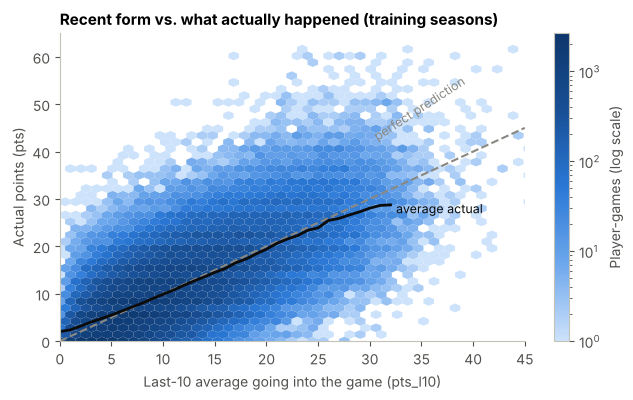

last-10 average as a prediction: MAE 4.56 pts, r = 0.70


,avg_last10,avg_actual,mae,games
pts_l10,,,,
"(-0.001, 5.0]",3.24,4.13,3.16,37588
"(5.0, 10.0]",7.46,7.62,4.20,59869
"(10.0, 15.0]",12.30,12.01,5.08,39301
"(15.0, 20.0]",17.27,16.67,5.72,20207
"(20.0, 25.0]",22.26,21.68,6.28,9756
"(25.0, 30.0]",27.12,26.02,6.70,4497
"(30.0, 60.0]",32.62,29.81,7.91,1209


In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4))
hb = ax.hexbin(train.pts_l10, train.pts, gridsize=45, bins='log', cmap=BLUES, mincnt=1, linewidths=0)
fig.colorbar(hb, ax=ax, label='Player-games (log scale)')
ax.plot([0, 45], [0, 45], ls='--', color=MUTED, lw=1.5)
ax.annotate('perfect prediction', (40, 40), xytext=(-4, 8), textcoords='offset points', ha='right',
            fontsize=9, color=MUTED, rotation=33)

# average actual points for each 1-point bucket of last-10 average
bucket = train.pts_l10.round()
by_bucket = train.groupby(bucket).pts.agg(['mean', 'size'])
by_bucket = by_bucket[by_bucket['size'] >= 200]
ax.plot(by_bucket.index, by_bucket['mean'], color=INK, lw=2)
ax.annotate('average actual', (by_bucket.index[-1], by_bucket['mean'].iloc[-1]), xytext=(4, -6),
            textcoords='offset points', fontsize=9, color=INK)
ax.set(xlabel='Last-10 average going into the game (pts_l10)', ylabel='Actual points (pts)',
       xlim=(0, 45), ylim=(0, 65), title='Recent form vs. what actually happened (training seasons)')
ax.grid(False)
plt.show()

print(f'last-10 average as a prediction: MAE {train["diff"].abs().mean():.2f} pts, r = {train.pts_l10.corr(train.pts):.2f}')
tiers = pd.cut(train.pts_l10, [0, 5, 10, 15, 20, 25, 30, 60], include_lowest=True)
train.groupby(tiers, observed=True).agg(avg_last10=('pts_l10', 'mean'), avg_actual=('pts', 'mean'),
                                         mae=('diff', lambda s: s.abs().mean()), games=('pts', 'size')).round(2)


**Takeaway:** Last-10 average is a decent but noisy bar (MAE 4.56, r = 0.70). The miss grows from ~3 pts for low scorers to ~8 for 30-ppg players, and the hottest scorers tend to come back down (30+ last-10 → 29.8 actual).

## TODO 3 — Opponent defense
Bin `opp_drtg_l10` into quintiles; average `pts - pts_l10` per bin. Do players score more vs bad defenses?

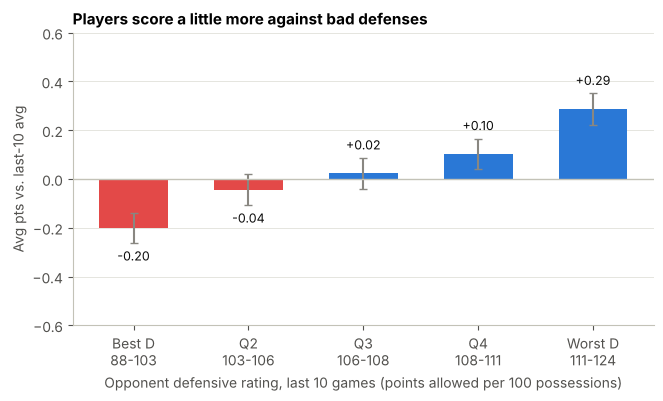

best-to-worst defense swing: 0.49 pts (for scale, the typical miss is ~4.5 pts)


same idea with opponent pace (slow -> fast): [-0.2, -0.02, 0.06, 0.1, 0.24]


In [6]:
quint = pd.qcut(train.opp_drtg_l10, 5)
g = train.groupby(quint, observed=True)['diff'].agg(['mean', 'std', 'size'])
names = ['Best D', 'Q2', 'Q3', 'Q4', 'Worst D']
labels = [f'{n}\n{iv.left:.0f}-{iv.right:.0f}' for n, iv in zip(names, g.index)]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
diff_bars(ax, g, labels)
ax.set(xlabel='Opponent defensive rating, last 10 games (points allowed per 100 possessions)',
       ylabel='Avg pts vs. last-10 avg', ylim=(-0.6, 0.6),
       title='Players score a little more against bad defenses')
plt.show()

swing = g['mean'].iloc[-1] - g['mean'].iloc[0]
print(f'best-to-worst defense swing: {swing:.2f} pts (for scale, the typical miss is ~4.5 pts)')
pace = train.groupby(pd.qcut(train.opp_pace_l10, 5), observed=True)['diff'].mean().round(2)
print('same idea with opponent pace (slow -> fast):', pace.tolist())


**Takeaway:** Yes, but barely: about −0.2 pts vs. the best defenses and +0.3 vs. the worst. That ~0.5-pt swing is a tenth of the typical 4.5-pt miss, and pace shows almost the same pattern, so overall DRtg adds little to the model.

## TODO 4 — Teammates out
Same idea with `tm_out_usg` bins. Does a player score more when a high-usage teammate sits?

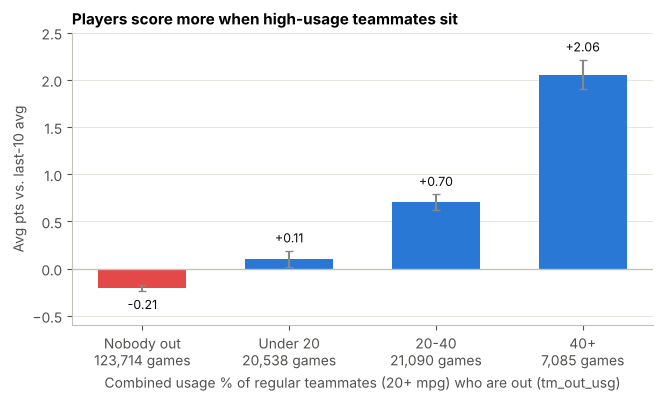

,games,beat_rate,avg_diff
tm_out_usg,,,
Nobody out,123714,0.439,-0.208
Under 20,20538,0.468,0.105
20-40,21090,0.503,0.702
40+,7085,0.590,2.057


In [7]:
out_bins = pd.cut(train.tm_out_usg, [-0.1, 0, 20, 40, 1000], labels=['Nobody out', 'Under 20', '20-40', '40+'])
g = train.groupby(out_bins, observed=True)['diff'].agg(['mean', 'std', 'size'])
labels = [f'{name}\n{n:,} games' for name, n in zip(g.index, g['size'])]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
diff_bars(ax, g, labels)
ax.set(xlabel='Combined usage % of regular teammates (20+ mpg) who are out (tm_out_usg)',
       ylabel='Avg pts vs. last-10 avg', ylim=(-0.6, 2.5),
       title='Players score more when high-usage teammates sit')
plt.show()

train.groupby(out_bins, observed=True).agg(games=('pts', 'size'), beat_rate=('beat', 'mean'),
                                            avg_diff=('diff', 'mean')).round(3)


**Takeaway:** Yes, and it's the clearest signal we have: with 40+ usage points of teammates out (roughly two starters), players beat their last-10 average 59% of the time by +2.1 pts, vs. 44% and −0.2 when nobody is out.

## TODO 5 — Data quality
Missing values, duplicate player-games, weird rows (e.g. usage > 60). Write down what you find.

,check,rows
0,Duplicate player-games (player_game_logs),0
1,Duplicate player-games (model_table),0
2,Points != 2*FGM + 3PM + FTM,0
3,Played rows with usage > 60%,392
4,"...of those, 5+ minutes",13
5,Played rows under 1 minute (usg set to NaN),3170
6,Rows over 48 minutes (overtime),379
7,DNP rows with no reason in comment,64
8,Player-seasons on 2+ teams (trades),940
9,"Seasons with fewer than 1,230 games",4


short seasons: {'2011-12': 990, '2012-13': 1229, '2019-20': 1059, '2020-21': 1080}
max minutes in a game: 60.33

missing share in model_table (features with any NaN):
usg_szn    0.0211
pts_szn    0.0158
usg_l5     0.0054
ts_l10     0.0014
usg_l10    0.0012


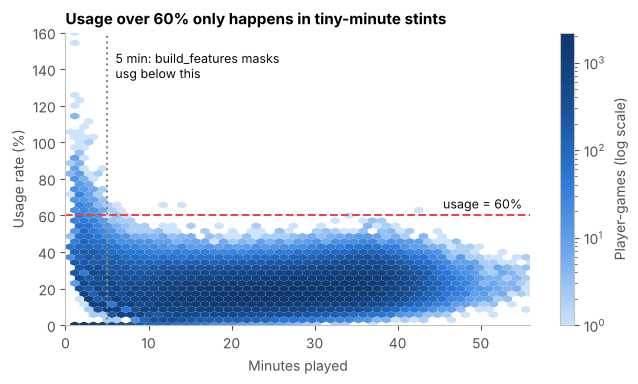

In [8]:
season_games = players.groupby('season').game_id.nunique()
checks = pd.DataFrame([
    ('Duplicate player-games (player_game_logs)', players.duplicated(['game_id', 'player_id']).sum()),
    ('Duplicate player-games (model_table)', model.duplicated(['game_id', 'player_id']).sum()),
    ('Points != 2*FGM + 3PM + FTM', ((2 * played.fgm + played.fg3m + played.ftm) != played.pts).sum()),
    ('Played rows with usage > 60%', (played.usg > 60).sum()),
    ('  ...of those, 5+ minutes', ((played.usg > 60) & (played['min'] >= 5)).sum()),
    ('Played rows under 1 minute (usg set to NaN)', (played['min'] < 1).sum()),
    ('Rows over 48 minutes (overtime)', (played['min'] > 48).sum()),
    ('DNP rows with no reason in comment', ((players.played == 0) & players.comment.isna()).sum()),
    ('Player-seasons on 2+ teams (trades)', (played.groupby(['player_id', 'season']).team.nunique() > 1).sum()),
    ('Seasons with fewer than 1,230 games', (season_games < 1230).sum()),
], columns=['check', 'rows'])
display(checks)
print('short seasons:', season_games[season_games < 1230].to_dict())
print('max minutes in a game:', played['min'].max())
print('\nmissing share in model_table (features with any NaN):')
miss = model.isna().mean()
print(miss[miss > 0].sort_values(ascending=False).round(4).to_string())

# chart: where do the absurd usage numbers come from?
u = played.dropna(subset=['usg'])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
hb = ax.hexbin(u['min'], u.usg, gridsize=50, bins='log', cmap=BLUES, mincnt=1, linewidths=0,
               extent=(0, 56, 0, 160))
fig.colorbar(hb, ax=ax, label='Player-games (log scale)')
ax.axhline(60, color=RED, lw=1.5, ls='--')
ax.axvline(5, color=MUTED, lw=1.5, ls=':')
ax.annotate('usage = 60%', (55, 60), xytext=(0, 5), textcoords='offset points', ha='right', fontsize=9, color=INK)
ax.annotate('5 min: build_features masks\nusg below this', (5, 150), xytext=(6, 0), textcoords='offset points',
            va='top', fontsize=9, color=INK)
ax.set(xlabel='Minutes played', ylabel='Usage rate (%)', xlim=(0, 56), ylim=(0, 160),
       title='Usage over 60% only happens in tiny-minute stints')
ax.grid(False)
plt.show()


**Takeaway:** The data is clean: no duplicates, every box score adds up, and 379 of the 392 "usage > 60%" rows are sub-5-minute cameos that `build_features.py` already masks. The short seasons are real (2011-12 lockout, a 2012-13 game that was never played, 2019-20 and 2020-21 COVID), and the main gap is no `pts_szn` for a player's first game of each season (1.6% of rows).

In [9]:
# Supporting numbers for the findings: when does a player beat his last-10 average?
def beat_table(bins):
    return train.groupby(bins, observed=True).agg(games=('pts', 'size'), beat_rate=('beat', 'mean'),
                                                  avg_diff=('diff', 'mean')).round(3)

print(f"overall: {train.beat.mean():.1%} of games beat the last-10 average "
      f"(median game {train.pts.median():.0f} pts vs. mean {train.pts.mean():.1f})")

streak = pd.cut(train.pts_l10 - train.pts_szn, [-100, -3, -1, 1, 3, 100],
                labels=['last-10 is 3+ below season avg', '1-3 below', 'about even', '1-3 above', '3+ above'])
display(beat_table(streak))

min_trend = pd.cut(train.min_l5 - train.min_l10, [-100, -3, -1, 1, 3, 100],
                   labels=['last-5 minutes 3+ below last-10', '1-3 below', 'about even', '1-3 above', '3+ above'])
display(beat_table(min_trend))


overall: 45.7% of games beat the last-10 average (median game 9 pts vs. mean 10.4)


,games,beat_rate,avg_diff
last-10 is 3+ below season avg,6383,0.595,2.242
1-3 below,28321,0.540,1.229
about even,82302,0.468,0.297
1-3 above,37185,0.405,-0.775
3+ above,15302,0.328,-2.279


,games,beat_rate,avg_diff
last-5 minutes 3+ below last-10,16363,0.377,-0.861
1-3 below,37638,0.437,-0.212
about even,63862,0.459,0.014
1-3 above,37631,0.481,0.328
3+ above,16933,0.513,0.864


## Findings

All numbers are from the training seasons (2015-16 to 2021-22). The question: **when does a player score more than his recent average?**

- **Less than half the time (46%).** Scoring is skewed: the median game (9 pts) is below the mean (10.4), so a plain last-10 average slightly overshoots a typical night.
- **When teammates are out.** This is the biggest pre-game signal. With 40+ usage points of regulars sidelined, players beat their last-10 average 59% of the time (+2.1 pts). With nobody out, it's 44% (−0.2).
- **When he's been cold, not hot.** If his last-10 average is 3+ pts above his season average, he beats it only 33% of the time (−2.3 pts). If it's 3+ below, he beats it 60% of the time (+2.2). Streaks regress, which is why `pts_szn` is the #2 feature. A "last-10 minus season" gap feature could help.
- **When his minutes are trending up.** Last-5 minutes 3+ above last-10: 51% beat (+0.9 pts). Trending down 3+: 38% (−0.9). Since minutes explain ~half of scoring (TODO 1), role changes matter.
- **Opponent defense barely matters in its current form.** Best-to-worst defense is only a ~0.5-pt swing, and opponent pace shows nearly the same pattern, so the two overlap. That's consistent with the MATCHUP group not helping the model. Defense by position (Option 2) is the next thing to try.
